# Hydraulic analysis of Koto city

In this notebook you will the different parts of the hydraulic analysis of Koto city, district within Tokyo metropolis.
Data used to calculate and determine hydraulic parameters were gatehered from the following sources:
- Precipitation and other atmospheric data courtesy of the Japan Meteorological Agency (Measuring station: Tokyo Observatory)
- Water level data: Water Information System courtesy of the Ministry of Land, Infrastructure, Transport and Tourism of Japan (Chart datum: Arakawa Peil [A.P.])
- Tidal data: Tide Table Tokyo courtesy of the Japan Meteorological Agency with an average spring tidal range of 187 cm or 1.87 m
- Geospatial data is taken from the Japan National Land Numerical Information dataset courtesy of the Ministry of Land, Infrastructure, Transport and Tourism of Japan

In [94]:
#Packages used in this analysis
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import scipy.stats as stats


In [95]:
# def parse_jp_datetime(year, dt):
#     if pd.isna(dt):
#         return pd.NaT
#     dt = str(dt).replace("年", "").replace("月", "/").replace("日", "").strip()
#     if dt.endswith(" 24:00"):
#         dt = dt.replace(" 24:00", " 00:00")
#         d = pd.to_datetime(f"{year}/{dt}", format="%Y/%m/%d %H:%M", errors="coerce")
#         if pd.notna(d):
#             return d + pd.Timedelta(days=1)
#         return d
#     return pd.to_datetime(f"{year}/{dt}", format="%Y/%m/%d %H:%M", errors="coerce")

In [96]:
# # Read and process hydraulic data for Sumida River (upstream)
# from io import StringIO

# with open("iwabuchi_WL_sumida.dat", "r", encoding="cp932", errors="replace") as f:
#     lines = f.readlines()

# valid_lines = []
# for line in lines:
#     s = line.strip()
#     if not s or s.startswith("#"):
#         continue
#     if s[:4].isdigit() and "," in s:
#         valid_lines.append(s)

# data_sumida_up = "\n".join(valid_lines)

# sumida_up = pd.read_csv(
#     StringIO(data_sumida_up),
#     sep=",",
#     header=None,
#     engine="python",
#     on_bad_lines="skip",
#     na_values=["-9999.00", "$", "-", "", "0.00"])

# # Select relevant columns and rename
# sumida_up = sumida_up[[0, 1, 3, 4, 6, 8, 10, 12, 14, 15]]
# sumida_up.columns = ['year', 'maxWL', 'date_maxWL', 'wetmeanWL+STD', 'wetmeanWL',
#                       'wetmeanWL-STD', 'drymeanWL', 'minWL', 'date_minWL','meanWL']

# # Clean and convert date columns to datetime format
# sumida_up["date_maxWL"] = [parse_jp_datetime(y, d)
#     for y, d in zip(sumida_up["year"], sumida_up["date_maxWL"])]

# sumida_up["date_minWL"] = [parse_jp_datetime(y, d)
#     for y, d in zip(sumida_up["year"], sumida_up["date_minWL"])]


In [97]:
# # Read and process hydraulic data for Sumida River (downstream)
# from io import StringIO

# with open("reiganjima_WL_sumida.dat", "r", encoding="cp932", errors="replace") as f:
#     lines = f.readlines()

# valid_lines = []
# for line in lines:
#     s = line.strip()
#     if not s or s.startswith("#"):
#         continue
#     if s[:4].isdigit() and "," in s:
#         valid_lines.append(s)

# data_sumida_down = "\n".join(valid_lines)

# sumida_down = pd.read_csv(
#     StringIO(data_sumida_down),
#     sep=",",
#     header=None,
#     engine="python",
#     on_bad_lines="skip",
#     na_values=["-9999.00", "$", "-", "", "0.00"])

# # Select relevant columns and rename
# sumida_down = sumida_down[[0, 1, 3, 4, 6, 8, 10, 12, 14, 15]]
# sumida_down.columns = ['year', 'maxWL', 'date_maxWL', 'wetmeanWL+STD', 'wetmeanWL',
#                        'wetmeanWL-STD', 'drymeanWL', 'minWL', 'date_minWL','meanWL']

# # Clean and convert date columns to datetime format
# sumida_down["date_maxWL"] = [parse_jp_datetime(y, d)
#     for y, d in zip(sumida_down["year"], sumida_down["date_maxWL"])]

# sumida_down["date_minWL"] = [parse_jp_datetime(y, d)
#     for y, d in zip(sumida_down["year"], sumida_down["date_minWL"])]




In [98]:
# # Read and process hydraulic data for Arakawa River (upstream)
# from io import StringIO

# with open("nanbata_WL_arakawa.dat", "r", encoding="cp932", errors="replace") as f:
#     lines = f.readlines()

# valid_lines = []
# for line in lines:
#     s = line.strip()
#     if not s or s.startswith("#"):
#         continue
#     if s[:4].isdigit() and "," in s:
#         valid_lines.append(s)

# data_arakawa_up = "\n".join(valid_lines)

# arakawa_up = pd.read_csv(
#     StringIO(data_arakawa_up),
#     sep=",",
#     header=None,
#     engine="python",
#     on_bad_lines="skip",
#     na_values=["-9999.00", "$", "-", "", "0.00"])

# # Select relevant columns and rename
# arakawa_up = arakawa_up[[0, 1, 3, 4, 6, 8, 10, 12, 14, 15]]
# arakawa_up.columns = ['year', 'maxWL', 'date_maxWL', 'wetmeanWL+STD', 'wetmeanWL',
#                       'wetmeanWL-STD', 'drymeanWL', 'minWL', 'date_minWL','meanWL']

# # Clean and convert date columns to datetime format
# arakawa_up["date_maxWL"] = [parse_jp_datetime(y, d)
#     for y, d in zip(arakawa_up["year"], arakawa_up["date_maxWL"])]

# arakawa_up["date_minWL"] = [parse_jp_datetime(y, d)
#     for y, d in zip(arakawa_up["year"], arakawa_up["date_minWL"])]

In [99]:
# # Read and process hydraulic data for Arakawa River (midstream)
# from io import StringIO

# with open("nishiarai_WL_arakawa.dat", "r", encoding="cp932", errors="replace") as f:
#     lines = f.readlines()

# valid_lines = []
# for line in lines:
#     s = line.strip()
#     if not s or s.startswith("#"):
#         continue
#     if s[:4].isdigit() and "," in s:
#         valid_lines.append(s)

# data_arakawa_mid = "\n".join(valid_lines)

# arakawa_mid = pd.read_csv(
#     StringIO(data_arakawa_mid),
#     sep=",",
#     header=None,
#     engine="python",
#     on_bad_lines="skip",
#     na_values=["-9999.00", "$", "-", "", "0.00"])


# # Select relevant columns and rename
# arakawa_mid = arakawa_mid[[0, 1, 3, 4, 6, 8, 10, 12, 14, 15]]
# arakawa_mid.columns = ['year', 'maxWL', 'date_maxWL', 'wetmeanWL+STD', 'wetmeanWL',
#                        'wetmeanWL-STD', 'drymeanWL', 'minWL', 'date_minWL','meanWL']

# # Clean and convert date columns to datetime format
# arakawa_mid["date_maxWL"] = [parse_jp_datetime(y, d)
#     for y, d in zip(arakawa_mid["year"], arakawa_mid["date_maxWL"])]

# arakawa_mid["date_minWL"] = [parse_jp_datetime(y, d)
#     for y, d in zip(arakawa_mid["year"], arakawa_mid["date_minWL"])]


In [100]:
# # Read and process hydraulic data for Arakawa River (downstream)
# from io import StringIO

# with open("onagigawa_WL_arakawa.dat", "r", encoding="cp932", errors="replace") as f:
#     lines = f.readlines()

# valid_lines = []
# for line in lines:
#     s = line.strip()
#     if not s or s.startswith("#"):
#         continue
#     if s[:4].isdigit() and "," in s:
#         valid_lines.append(s)

# data_arakawa_down = "\n".join(valid_lines)

# arakawa_down = pd.read_csv(
#     StringIO(data_arakawa_down),
#     sep=",",
#     header=None,
#     engine="python",
#     on_bad_lines="skip",
#     na_values=["-9999.00", "$", "-", "", "0.00"])

# # Select relevant columns and rename
# arakawa_down = arakawa_down[[0, 1, 3, 4, 6, 8, 10, 12, 14, 15]]
# arakawa_down.columns = ['year', 'maxWL', 'date_maxWL', 'wetmeanWL+STD', 'wetmeanWL',
#                         'wetmeanWL-STD', 'drymeanWL', 'minWL', 'date_minWL','meanWL']

# # Clean and convert date columns to datetime format
# arakawa_down["date_maxWL"] = [parse_jp_datetime(y, d)
#     for y, d in zip(arakawa_down["year"], arakawa_down["date_maxWL"])]

# arakawa_down["date_minWL"] = [parse_jp_datetime(y, d)
#     for y, d in zip(arakawa_down["year"], arakawa_down["date_minWL"])]


In [101]:
# #Saving dataframes to CSV files
# sumida_up.to_csv('sumida_upstream_iwabuchi.csv', index=False)
# sumida_down.to_csv('sumida_downstream_reiganjima.csv', index=False)
# arakawa_up.to_csv('arakawa_upstream_nanbata.csv', index=False)
# arakawa_mid.to_csv('arakawa_midstream_nishiarai.csv', index=False)
# arakawa_down.to_csv('arakawa_downstream_onagigawa.csv', index=False)

In [102]:
# # Read and process hydraulic data for Tokyo (1872-1906)
# from io import StringIO

# with open("1872-1906.csv", "r", encoding="cp932", errors="replace") as f:
#     lines = f.readlines()

# valid_lines = []
# for line in lines:
#     s = line.strip()
#     if not s or s.startswith("#"):
#         continue
#     if s[:4].isdigit() and "," in s:
#         valid_lines.append(s)

# data_1872_1906 = "\n".join(valid_lines)

# tokyo_P_1872_1906 = pd.read_csv(
#     StringIO(data_1872_1906),
#     sep=",",
#     header=None,
#     engine="python",
#     on_bad_lines="skip",
#     na_values=["-9999.00", "$", "-", "", "0.00"])


# # Select relevant columns and rename
# tokyo_P_1872_1906 = tokyo_P_1872_1906[[0, 1, 5]]
# tokyo_P_1872_1906.columns = ['date', 'daily_total', 'hourly_max']

# # Convert date column to datetime format
# tokyo_P_1872_1906["date"] = pd.to_datetime(tokyo_P_1872_1906["date"].astype(str).str.strip(),
#                                             format="%Y/%m/%d", errors="coerce")


In [103]:
# #Read and process hydraulic data for Tokyo (1907-1966)
# from io import StringIO

# with open("1907-1966.csv", "r", encoding="cp932", errors="replace") as f:
#     lines = f.readlines()

# valid_lines = []
# for line in lines:
#     s = line.strip()
#     if not s or s.startswith("#"):
#         continue
#     if s[:4].isdigit() and "," in s:
#         valid_lines.append(s)

# data_1907_1966 = "\n".join(valid_lines)

# tokyo_P_1907_1966 = pd.read_csv(
#     StringIO(data_1907_1966),
#     sep=",",
#     header=None,
#     engine="python",
#     on_bad_lines="skip",
#     na_values=["-9999.00", "$", "-", "", "0.00"])


# # Select relevant columns and rename
# tokyo_P_1907_1966 = tokyo_P_1907_1966[[0, 1, 5]]
# tokyo_P_1907_1966.columns = ['date', 'daily_total', 'hourly_max']

# # Convert date column to datetime format
# tokyo_P_1907_1966["date"] = pd.to_datetime(tokyo_P_1907_1966["date"].astype(str).str.strip(),
#                                             format="%Y/%m/%d", errors="coerce")


In [104]:
# # Read and process hydraulic data for Tokyo (1967-2026)
# from io import StringIO

# with open("1967-2026.csv", "r", encoding="cp932", errors="replace") as f:
#     lines = f.readlines()

# valid_lines = []
# for line in lines:
#     s = line.strip()
#     if not s or s.startswith("#"):
#         continue
#     if s[:4].isdigit() and "," in s:
#         valid_lines.append(s)

# data_1967_2026 = "\n".join(valid_lines)

# tokyo_P_1967_2026 = pd.read_csv(
#     StringIO(data_1967_2026),
#     sep=",",
#     header=None,
#     engine="python",
#     on_bad_lines="skip",
#     na_values=["-9999.00", "$", "-", "", "0.00"])

# # Select relevant columns and rename
# tokyo_P_1967_2026 = tokyo_P_1967_2026[[0, 1, 5]]
# tokyo_P_1967_2026.columns = ['date', 'daily_total', 'hourly_max']

# # Convert date column to datetime format
# tokyo_P_1967_2026["date"] = pd.to_datetime(tokyo_P_1967_2026["date"].astype(str).str.strip(),
#                                             format="%Y/%m/%d", errors="coerce")

In [105]:
# #Combine all Tokyo datasets into a single DataFrame and save to csv
# tokyo_P_all = pd.concat([tokyo_P_1872_1906, tokyo_P_1907_1966, tokyo_P_1967_2026], ignore_index=True)
# Tokyo_P_daily = tokyo_P_all[["date", "daily_total", "hourly_max"]]
# Tokyo_P_daily.to_csv('Tokyo_P_daily.csv', index=False)

In [106]:
#Load csv files into dataframes
sumida_up = pd.read_csv('sumida_upstream_iwabuchi.csv')
sumida_down = pd.read_csv('sumida_downstream_reiganjima.csv')
arakawa_up = pd.read_csv('arakawa_upstream_nanbata.csv')
arakawa_mid = pd.read_csv('arakawa_midstream_nishiarai.csv')
arakawa_down = pd.read_csv('arakawa_downstream_onagigawa.csv')

In [107]:
#Removing rows with NaN values in the 'maxWL' column
sumida_up = sumida_up.dropna(subset=['maxWL'])
sumida_down = sumida_down.dropna(subset=['maxWL'])
arakawa_up = arakawa_up.dropna(subset=['maxWL'])
arakawa_mid = arakawa_mid.dropna(subset=['maxWL'])
arakawa_down = arakawa_down.dropna(subset=['maxWL'])

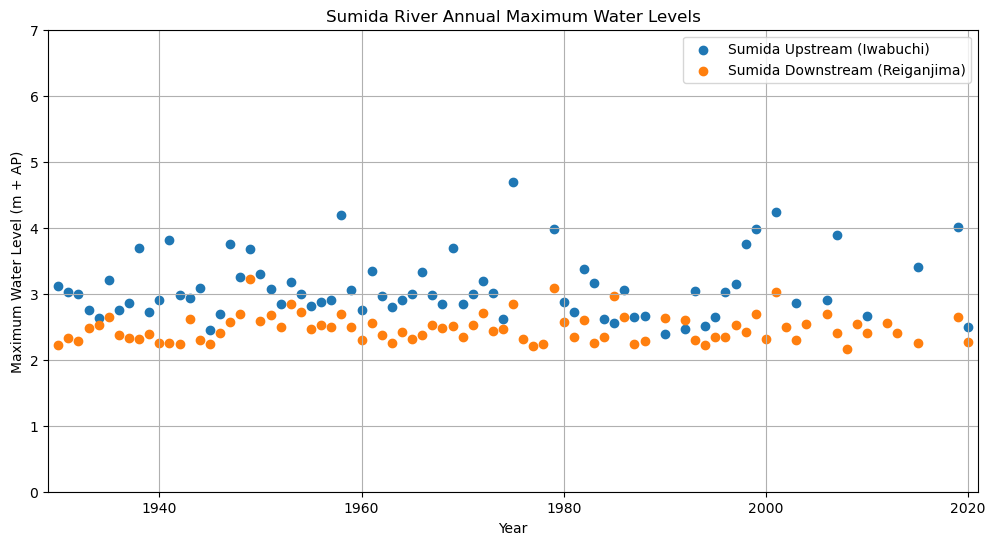

In [108]:
#Sumida river water level analysis
plt.figure(figsize=(12, 6))
plt.scatter(sumida_up['year'], sumida_up['maxWL'], label='Sumida Upstream (Iwabuchi)')
plt.scatter(sumida_down['year'], sumida_down['maxWL'], label='Sumida Downstream (Reiganjima)')
plt.title('Sumida River Annual Maximum Water Levels')
plt.xlabel('Year')
plt.ylabel('Maximum Water Level (m + AP)')
plt.xlim(sumida_down['year'].min()-1, sumida_up['year'].max()+1)
plt.ylim(0, 7)
plt.grid()
plt.legend()
plt.show()

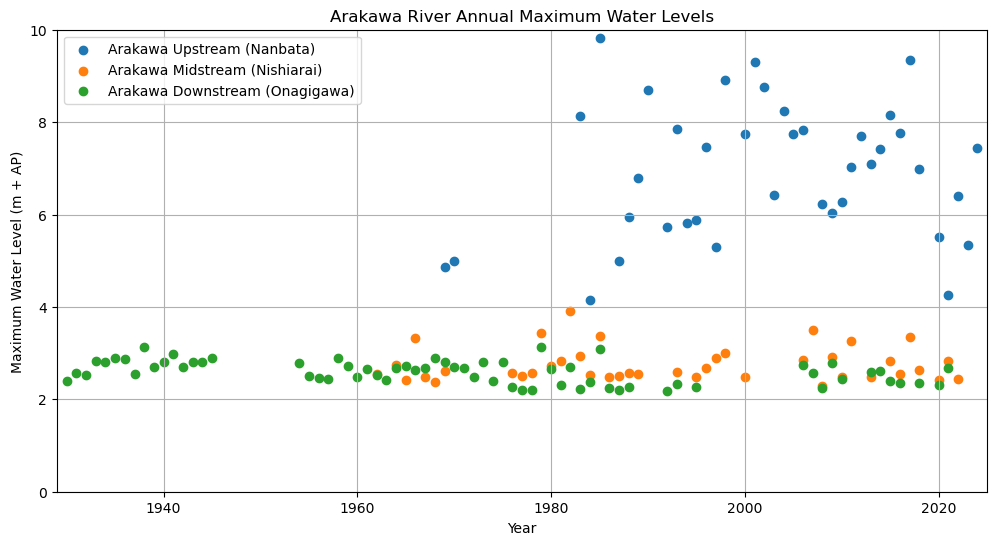

In [109]:
#Arakawa river water level analysis
plt.figure(figsize=(12, 6))
plt.scatter(arakawa_up['year'], arakawa_up['maxWL'], label='Arakawa Upstream (Nanbata)')
plt.scatter(arakawa_mid['year'], arakawa_mid['maxWL'], label='Arakawa Midstream (Nishiarai)')
plt.scatter(arakawa_down['year'], arakawa_down['maxWL'], label='Arakawa Downstream (Onagigawa)')
plt.title('Arakawa River Annual Maximum Water Levels')
plt.xlabel('Year')
plt.ylabel('Maximum Water Level (m + AP)')
plt.xlim(arakawa_down['year'].min()-1, arakawa_up['year'].max()+1)
plt.ylim(0, 10)
plt.grid()
plt.legend()
plt.show()

In [110]:
def ecdf(data):
    """Compute the empirical cumulative distribution function (ECDF) for a one-dimensional array of measurements."""
    n = len(data)
    x = np.sort(data)
    y = np.arange(1, n + 1) / n
    return x, y

In [111]:
# Load monthly total precipitation data for analysis
P_tokyo = pd.read_csv('monthly_total_P_tokyo.csv', delimiter=';', encoding='utf-8')

dict_months = {1: 'Jan', 2: 'Feb', 3: 'Mar', 4: 'Apr', 5: 'May', 6: 'Jun',
               7: 'Jul', 8: 'Aug', 9: 'Sep', 10: 'Oct', 11: 'Nov', 12: 'Dec'}
mean_permonth = np.array([])
for month, name in dict_months.items():
    mean_permonth = np.append(mean_permonth, P_tokyo[name].mean())
total_annual_mean_prcp = P_tokyo['Annual'].mean()

# print(mean_permonth)
# print(total_annual_mean_prcp)

In [112]:
#Load Tokyo daily precipitation data and plot daily total and hourly max precipitation
Tokyo_P_daily = pd.read_csv('Tokyo_P_daily.csv')

#Drop NaN values from the daily total and hourly max precipitation columns
Tokyo_P_daily = Tokyo_P_daily.dropna(subset=['daily_total', 'hourly_max'])



In [113]:
#plot daily total and hourly max precipitation
# plt.figure(figsize=(12, 6))
# plt.plot(Tokyo_P_daily['date'], Tokyo_P_daily['daily_total'], label='Daily Total Precipitation (mm)', color='blue')
# plt.plot(Tokyo_P_daily['date'], Tokyo_P_daily['hourly_max'], label='Hourly Max Precipitation (mm)', color='orange')
# plt.title('Tokyo Daily Precipitation (1872-2026)')
# plt.xlabel('Date')
# plt.ylabel('Precipitation (mm)')
# plt.xlim(Tokyo_P_daily['date'].min(), Tokyo_P_daily['date'].max())
# plt.grid()
# plt.legend()
# plt.xticks(Tokyo_P_daily['date'].dt.year, Tokyo_P_daily['date'].dt.year)
# plt.show()

In [114]:
#Sampling the daily precipitation data for yearly maxima 
Tokyo_P_daily['year'] = Tokyo_P_daily['date'].str[:4].astype(int)
Tokyo_P_yearly_idxmax = Tokyo_P_daily.groupby('year')['daily_total'].idxmax()
Tokyo_P_yearly_max = Tokyo_P_daily.loc[Tokyo_P_yearly_idxmax]

#Fit to Generalized Extreme Value (GEV) distribution
params_ym_Tokyo = stats.genextreme.fit(Tokyo_P_yearly_max['daily_total'].dropna())

x_gev_daily = np.linspace(ecdf(Tokyo_P_yearly_max['daily_total'].dropna())[0].min(), ecdf(Tokyo_P_yearly_max['daily_total'].dropna())[0].max(), 100)
cdf_gev_daily = stats.genextreme.cdf(x_gev_daily, *params_ym_Tokyo)

In [115]:
#Resample the daily precipitation data for a rolling 72-hour sum and calculate the maximum for each year
#Copy the Tokyo_P_daily DataFrame to avoid modifying the original data
daily = Tokyo_P_daily.copy()

daily["date"] = pd.to_datetime(daily["date"].astype(str).str.strip(), errors="coerce")
# daily.head()
daily["daily_total"] = pd.to_numeric(daily["daily_total"], errors="coerce")

daily = (daily.dropna(subset=["date", "daily_total"]).sort_values("date")
         .drop_duplicates("date").set_index("date"))


# daily["date"] = pd.to_datetime(daily["date"].astype(str).str.strip(), errors="coerce")

#Check for missing dates
full_dates = pd.date_range(daily.index.min(), daily.index.max(), freq="D")
missing_dates = full_dates.difference(daily.index)

#Calculate the rolling 72-hour sum of daily precipitation
daily["precip_72h"] = (daily["daily_total"].rolling(window=3, min_periods=3).sum())

#Extract the maximum 72-hour precipitation for each year
annual_72h_max = (daily["precip_72h"].groupby(daily.index.year).max().dropna())

In [116]:
#Fit the annual 72-hour maximum precipitation to a GEV distribution
params_72h_Tokyo = stats.genextreme.fit(annual_72h_max.dropna())

#Calculate precipitation for different return periods using the GEV distribution
return_periods = [50, 100, 200, 500, 1000, 2000, 5000, 10000, 15000, 20000, 25000, 30000, 40000, 50000, 60000, 70000, 80000, 90000, 100000]
precipitation_return_periods = {}
for i, T in enumerate(return_periods):
    p = 1 - 1/T
    precipitation_return_periods[T] = stats.genextreme.ppf(p, *params_72h_Tokyo)
    print(f"Return period:{T} years, 72-hour Precipitation: {precipitation_return_periods[T]:.2f} mm")

Return period:50 years, 72-hour Precipitation: 359.35 mm
Return period:100 years, 72-hour Precipitation: 396.21 mm
Return period:200 years, 72-hour Precipitation: 433.08 mm
Return period:500 years, 72-hour Precipitation: 481.94 mm
Return period:1000 years, 72-hour Precipitation: 519.05 mm
Return period:2000 years, 72-hour Precipitation: 556.28 mm
Return period:5000 years, 72-hour Precipitation: 605.72 mm
Return period:10000 years, 72-hour Precipitation: 643.29 mm
Return period:15000 years, 72-hour Precipitation: 665.34 mm
Return period:20000 years, 72-hour Precipitation: 681.01 mm
Return period:25000 years, 72-hour Precipitation: 693.18 mm
Return period:30000 years, 72-hour Precipitation: 703.14 mm
Return period:40000 years, 72-hour Precipitation: 718.88 mm
Return period:50000 years, 72-hour Precipitation: 731.10 mm
Return period:60000 years, 72-hour Precipitation: 741.10 mm
Return period:70000 years, 72-hour Precipitation: 749.56 mm
Return period:80000 years, 72-hour Precipitation: 75

In [117]:
# Return period calculation for GEV distribution of yearly maxima (24 hours)
for i, T in enumerate(return_periods):
    p = 1 - 1/T
    precipitation_return_periods[T] = stats.genextreme.ppf(p, *params_ym_Tokyo)
    print(f"Return period:{T} years, 24-hour Precipitation: {precipitation_return_periods[T]:.2f} mm")

Return period:50 years, 24-hour Precipitation: 253.69 mm
Return period:100 years, 24-hour Precipitation: 282.51 mm
Return period:200 years, 24-hour Precipitation: 311.38 mm
Return period:500 years, 24-hour Precipitation: 349.74 mm
Return period:1000 years, 24-hour Precipitation: 378.93 mm
Return period:2000 years, 24-hour Precipitation: 408.28 mm
Return period:5000 years, 24-hour Precipitation: 447.33 mm
Return period:10000 years, 24-hour Precipitation: 477.07 mm
Return period:15000 years, 24-hour Precipitation: 494.55 mm
Return period:20000 years, 24-hour Precipitation: 506.99 mm
Return period:25000 years, 24-hour Precipitation: 516.65 mm
Return period:30000 years, 24-hour Precipitation: 524.56 mm
Return period:40000 years, 24-hour Precipitation: 537.07 mm
Return period:50000 years, 24-hour Precipitation: 546.80 mm
Return period:60000 years, 24-hour Precipitation: 554.76 mm
Return period:70000 years, 24-hour Precipitation: 561.50 mm
Return period:80000 years, 24-hour Precipitation: 56

In [118]:
#POT method for daily precipitation values of Tokyo 72 hour rolling sum
from scipy import signal
threshold_72h = 100
declustering_window = 3  # days
peaks_72h, _ = signal.find_peaks(daily["precip_72h"].values, height=threshold_72h, distance=declustering_window)

# Fitting the peaks to a Generalized Pareto Distribution (GPD)
params_gpd_72h = stats.genpareto.fit(daily["precip_72h"].values[peaks_72h] - threshold_72h)

x_gpd_72h = np.linspace(0, daily["precip_72h"].values[peaks_72h].max() - threshold_72h, 100)
cdf_gpd_72h = stats.genpareto.cdf(x_gpd_72h, *params_gpd_72h)

#Calculate precipitation for different return periods using the GPD distribution
precipitation_return_periods_gpd = {}

for i, T in enumerate(return_periods):
    p = 1 - 1/T
    precipitation_return_periods_gpd[T] = threshold_72h + stats.genpareto.ppf(p, *params_gpd_72h)
    print(f"Return period:{T} years, 72-hour Precipitation (GPD): {precipitation_return_periods_gpd[T]:.2f} mm")



Return period:50 years, 72-hour Precipitation (GPD): 314.83 mm
Return period:100 years, 72-hour Precipitation (GPD): 356.57 mm
Return period:200 years, 72-hour Precipitation (GPD): 399.51 mm
Return period:500 years, 72-hour Precipitation (GPD): 458.15 mm
Return period:1000 years, 72-hour Precipitation (GPD): 503.98 mm
Return period:2000 years, 72-hour Precipitation (GPD): 551.12 mm
Return period:5000 years, 72-hour Precipitation (GPD): 615.50 mm
Return period:10000 years, 72-hour Precipitation (GPD): 665.81 mm
Return period:15000 years, 72-hour Precipitation (GPD): 695.91 mm
Return period:20000 years, 72-hour Precipitation (GPD): 717.56 mm
Return period:25000 years, 72-hour Precipitation (GPD): 734.54 mm
Return period:30000 years, 72-hour Precipitation (GPD): 748.52 mm
Return period:40000 years, 72-hour Precipitation (GPD): 770.79 mm
Return period:50000 years, 72-hour Precipitation (GPD): 788.24 mm
Return period:60000 years, 72-hour Precipitation (GPD): 802.62 mm
Return period:70000 ye

In [119]:
#Goodness of fit test for GEV and GPD distributions
gev_sample = annual_72h_max.dropna().to_numpy()

# Perform Kolmogorov-Smirnov test for GEV distribution
ks_stat_gev, ks_p_value_gev = stats.kstest(gev_sample, lambda x: stats.genextreme.cdf(x, *params_72h_Tokyo))

# Perform Kolmogorov-Smirnov test for GPD distribution
ks_stat_gpd, ks_p_value_gpd = stats.kstest(daily["precip_72h"].values[peaks_72h] - threshold_72h, lambda x: stats.genpareto.cdf(x, *params_gpd_72h))

print(f"GEV KS Statistic: {ks_stat_gev:.4f}, p-value: {ks_p_value_gev:.4f}")
print(f"GPD KS Statistic: {ks_stat_gpd:.4f}, p-value: {ks_p_value_gpd:.4f}")

GEV KS Statistic: 0.0532, p-value: 0.8097
GPD KS Statistic: 0.0432, p-value: 0.5488


In [120]:
# def bootstrap_ks_pvalue(sample, fit_function, cdf_function,
#                         rvs_function, n_boot=5000, seed=42):
#     sample = np.asarray(sample, dtype=float)
#     sample = sample[np.isfinite(sample)]

#     rng = np.random.default_rng(seed)

#     # Fit the model to the observed sample
#     observed_params = fit_function(sample)

#     observed_ks = stats.kstest(
#         sample,
#         lambda x: cdf_function(x, observed_params)
#     ).statistic

#     bootstrap_statistics = []

#     for _ in range(n_boot):
#         # Simulate data from the fitted model
#         simulated_sample = rvs_function(
#             observed_params,
#             len(sample),
#             rng
#         )

#         # Refit the model to the simulated data
#         simulated_params = fit_function(simulated_sample)

#         # Calculate the KS statistic after refitting
#         simulated_ks = stats.kstest(
#             simulated_sample,
#             lambda x: cdf_function(x, simulated_params)
#         ).statistic

#         bootstrap_statistics.append(simulated_ks)

#     bootstrap_statistics = np.asarray(bootstrap_statistics)

#     # Larger KS statistics indicate poorer fit
#     p_value = (
#         1 + np.sum(bootstrap_statistics >= observed_ks)
#     ) / (len(bootstrap_statistics) + 1)

#     return observed_ks, p_value, bootstrap_statistics

In [121]:
# #GEV distribution functions for bootstrap KS test
# gev_sample = annual_72h_max.dropna().to_numpy()

# ks_gev, p_gev, gev_bootstrap = bootstrap_ks_pvalue(sample=gev_sample,
#     fit_function=lambda x: stats.genextreme.fit(x),
#     cdf_function=lambda x, params: stats.genextreme.cdf(x, *params),
#     rvs_function=lambda params, n, rng:stats.genextreme.rvs(*params, size=n, random_state=rng))

# print(f"GEV bootstrap KS statistic: {ks_gev:.4f}")
# print(f"GEV bootstrap p-value: {p_gev:.4f}")

In [122]:
# #GPD distribution functions for bootstrap KS test
# gpd_sample = (daily["precip_72h"].values[peaks_72h] - threshold_72h)

# gpd_sample = gpd_sample[np.isfinite(gpd_sample)]

# ks_gpd, p_gpd, gpd_bootstrap = bootstrap_ks_pvalue(sample=gpd_sample,
#     fit_function=lambda x: stats.genpareto.fit(x),
#     cdf_function=lambda x, params: stats.genpareto.cdf(x, *params),
#     rvs_function=lambda params, n, rng:stats.genpareto.rvs(*params, size=n, random_state=rng))

# print(f"GPD bootstrap KS statistic: {ks_gpd:.4f}")
# print(f"GPD bootstrap p-value: {p_gpd:.4f}")

In [123]:
# Calculate the hourly maximum precipitation for each year
Tokyo_P_hourly_idxmax = Tokyo_P_daily.groupby('year')['hourly_max'].idxmax()
Tokyo_P_hourly_max = Tokyo_P_daily.loc[Tokyo_P_hourly_idxmax]

#Fit the hourly maximum precipitation to a GEV distribution
params_hourly_Tokyo = stats.genextreme.fit(Tokyo_P_hourly_max['hourly_max'].dropna())

x_gev_hourly = np.linspace(ecdf(Tokyo_P_hourly_max['hourly_max'].dropna())[0].min(), ecdf(Tokyo_P_hourly_max['hourly_max'].dropna())[0].max(), 100)
cdf_gev_hourly = stats.genextreme.cdf(x_gev_hourly, *params_hourly_Tokyo)

#Calculate precipitation for different return periods using the GEV distribution for hourly maximum precipitation
precipitation_return_periods_hourly = {}
for i, T in enumerate(return_periods):
    p = 1 - 1/T
    precipitation_return_periods_hourly[T] = stats.genextreme.ppf(p, *params_hourly_Tokyo)
    print(f"Return period:{T} years, Hourly Max Precipitation: {precipitation_return_periods_hourly[T]:.2f} mm")

Return period:50 years, Hourly Max Precipitation: 84.15 mm
Return period:100 years, Hourly Max Precipitation: 95.43 mm
Return period:200 years, Hourly Max Precipitation: 107.28 mm
Return period:500 years, Hourly Max Precipitation: 123.92 mm
Return period:1000 years, Hourly Max Precipitation: 137.29 mm
Return period:2000 years, Hourly Max Precipitation: 151.39 mm
Return period:5000 years, Hourly Max Precipitation: 171.20 mm
Return period:10000 years, Hourly Max Precipitation: 187.15 mm
Return period:15000 years, Hourly Max Precipitation: 196.87 mm
Return period:20000 years, Hourly Max Precipitation: 203.95 mm
Return period:25000 years, Hourly Max Precipitation: 209.56 mm
Return period:30000 years, Hourly Max Precipitation: 214.21 mm
Return period:40000 years, Hourly Max Precipitation: 221.68 mm
Return period:50000 years, Hourly Max Precipitation: 227.59 mm
Return period:60000 years, Hourly Max Precipitation: 232.49 mm
Return period:70000 years, Hourly Max Precipitation: 236.69 mm
Return

In [124]:
#KS test for hourly maximum precipitation GEV distribution
gev_sample_hourly = Tokyo_P_hourly_max['hourly_max'].dropna().to_numpy()

# Perform Kolmogorov-Smirnov test for GEV distribution of hourly maximum precipitation
ks_stat_gev_hourly, ks_p_value_gev_hourly = stats.kstest(gev_sample_hourly, lambda x: stats.genextreme.cdf(x, *params_hourly_Tokyo))

print(f"Hourly Max GEV KS Statistic: {ks_stat_gev_hourly:.4f}, p-value: {ks_p_value_gev_hourly:.4f}")

Hourly Max GEV KS Statistic: 0.0452, p-value: 0.9253


In [125]:
#Print precipitation data corresponding to Typhoon Fitow hitting Tokyo
precip_7_9_2007 = Tokyo_P_daily[Tokyo_P_daily['date'] == '2007-09-07'][['date', 'daily_total', 'hourly_max']]
print("Precipitation data for 7th September 2007:")
print(precip_7_9_2007)

#Summing up the precipitation data a week surrounding the typhoon event
week_surrounding_typhoon = Tokyo_P_daily[(Tokyo_P_daily['date'] >= '2007-09-04') & (Tokyo_P_daily['date'] <= '2007-09-10')]
total_precip_week_surrounding = week_surrounding_typhoon['daily_total'].sum()
print(f"Total precipitation from 4th to 10th September 2007: {total_precip_week_surrounding:.2f} mm")

Precipitation data for 7th September 2007:
             date  daily_total  hourly_max
49557  2007-09-07         50.0        12.0
Total precipitation from 4th to 10th September 2007: 160.50 mm


In [126]:
#Restructure into new dataframe with three columns: date, precipitation and annual_p
P_monthly = pd.DataFrame({"date": pd.date_range(start='1875-01-01', end='2025-12-31', freq='ME'),
    "precipitation": P_tokyo[["Jan", "Feb", "Mar", "Apr", "May", "Jun",
         "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]].to_numpy().flatten()})

P_monthly = P_monthly.iloc[5:].reset_index(drop=True)  # Reset index after slicing to remove missing values at the beginning of the dataset

# wet_year_total = P_monthly.groupby(P_monthly['date'].dt.year)['precipitation'].sum().reset_index() # from october to september rolling average


In [127]:
# #Sampling for yearly precipitation maxima
# P_monthly['year'] = P_monthly['date'].dt.isocalendar().year
# P_monthly_idxmax = P_monthly.groupby('year')['precipitation'].idxmax()
# P_monthly_yearly_max = P_monthly.loc[P_monthly_idxmax].reset_index(drop=True)


# plt.figure(figsize=(12, 6))
# plt.plot(P_monthly['date'], P_monthly['precipitation'], label='Monthly Precipitation')
# plt.plot(P_monthly_yearly_max['date'], P_monthly_yearly_max['precipitation'], 'kx', label='Yearly Maxima')
# plt.title('Monthly Precipitation and Yearly Maxima in Tokyo')
# plt.xlabel('Date')
# plt.ylabel('Precipitation (mm)')
# plt.grid()
# plt.show()


In [128]:
# #Fit GEV distribution to the yearly maxima of precipitation
# params_ym = stats.genextreme.fit(P_monthly_yearly_max['precipitation'])

# x_gev = np.linspace(min(ecdf(P_monthly_yearly_max['precipitation'])[0]), max(ecdf(P_monthly_yearly_max['precipitation'])[0]), 100)
# cdf_gev = stats.genextreme.cdf(x_gev, *params_ym)


# plt.figure(figsize=(12, 6))
# plt.plot(x_gev, 1-cdf_gev, label='Gumbel CDF')
# plt.step(ecdf(P_monthly_yearly_max['precipitation'])[0], 1 - ecdf(P_monthly_yearly_max['precipitation'])[1], label='Empirical CDF', where='post')
# plt.xlabel('Precipitation')
# plt.ylabel('Cumulative Probability')
# plt.title('Fitted GEV Distribution')
# plt.yscale('log')
# plt.legend()
# plt.grid(True)
# plt.show()

In [129]:
# #Fit Gumbel distribution to yearly maxima of water levels for the Sumida river
# params_sumida_up = stats.gumbel_r.fit(sumida_up['maxWL'])
# params_sumida_down = stats.gumbel_r.fit(sumida_down['maxWL'])

# x_sumida_up = np.linspace(min(ecdf(sumida_up['maxWL'])[0]), max(ecdf(sumida_up['maxWL'])[0]), 100)
# x_sumida_down = np.linspace(min(ecdf(sumida_down['maxWL'])[0]), max(ecdf(sumida_down['maxWL'])[0]), 100)
# cdf_sumida_up = stats.gumbel_r.cdf(x_sumida_up, *params_sumida_up)
# cdf_sumida_down = stats.gumbel_r.cdf(x_sumida_down, *params_sumida_down)

# fig, axes = plt.subplots(1,2, figsize=(12, 6))
# axes[0].plot(x_sumida_up, 1-cdf_sumida_up, label='Sumida Upstream (Iwabuchi) Gumbel CDF')
# axes[1].plot(x_sumida_down, 1-cdf_sumida_down, label='Sumida Downstream (Reiganjima) Gumbel CDF')
# axes[0].step(ecdf(sumida_up['maxWL'])[0], 1 - ecdf(sumida_up['maxWL'])[1], label='Sumida Upstream Empirical', where='post')
# axes[1].step(ecdf(sumida_down['maxWL'])[0], 1 - ecdf(sumida_down['maxWL'])[1], label='Sumida Downstream Empirical', where='post')
# axes[0].set_xlabel('Water Level (m + AP)')
# axes[0].set_ylabel('Cumulative Probability')
# axes[1].set_xlabel('Water Level (m + AP)')
# axes[1].set_ylabel('Cumulative Probability')
# plt.suptitle('Fitted Gumbel Distribution for Sumida River Water Levels')
# axes[0].set_yscale('log')
# axes[1].set_yscale('log')
# axes[0].legend()
# axes[1].legend()
# axes[0].grid(True)
# axes[1].grid(True)
# plt.show()

In [130]:
# #Fit Gumbel distribution to yearly maxima of water levels for the Arakawa river
# params_arakawa_up = stats.gumbel_r.fit(arakawa_up['maxWL'])
# params_arakawa_mid = stats.gumbel_r.fit(arakawa_mid['maxWL'])
# params_arakawa_down = stats.gumbel_r.fit(arakawa_down['maxWL'])

# x_arakawa_up = np.linspace(min(ecdf(arakawa_up['maxWL'])[0]), max(ecdf(arakawa_up['maxWL'])[0]), 100)
# x_arakawa_mid = np.linspace(min(ecdf(arakawa_mid['maxWL'])[0]), max(ecdf(arakawa_mid['maxWL'])[0]), 100)
# x_arakawa_down = np.linspace(min(ecdf(arakawa_down['maxWL'])[0]), max(ecdf(arakawa_down['maxWL'])[0]), 100)
# cdf_arakawa_up = stats.gumbel_r.cdf(x_arakawa_up, *params_arakawa_up)
# cdf_arakawa_mid = stats.gumbel_r.cdf(x_arakawa_mid, *params_arakawa_mid)
# cdf_arakawa_down = stats.gumbel_r.cdf(x_arakawa_down, *params_arakawa_down)


# fig, axes = plt.subplots(1,3, figsize=(18, 6))
# axes[0].plot(x_arakawa_up, 1-cdf_arakawa_up, label='Arakawa Upstream (Nanbata) Gumbel CDF')
# axes[1].plot(x_arakawa_mid, 1-cdf_arakawa_mid, label='Arakawa Midstream (Nishiarai) Gumbel CDF')
# axes[2].plot(x_arakawa_down, 1-cdf_arakawa_down, label='Arakawa Downstream (Onagigawa) Gumbel CDF')
# axes[0].step(ecdf(arakawa_up['maxWL'])[0], 1 - ecdf(arakawa_up['maxWL'])[1], label='Arakawa Upstream Empirical', where='post')
# axes[1].step(ecdf(arakawa_mid['maxWL'])[0], 1 - ecdf(arakawa_mid['maxWL'])[1], label='Arakawa Midstream Empirical', where='post')
# axes[2].step(ecdf(arakawa_down['maxWL'])[0], 1 - ecdf(arakawa_down['maxWL'])[1], label='Arakawa Downstream Empirical', where='post')
# axes[0].set_xlabel('Water Level (m + AP)')
# axes[0].set_ylabel('Cumulative Probability')
# axes[1].set_xlabel('Water Level (m + AP)')
# axes[1].set_ylabel('Cumulative Probability')
# axes[2].set_xlabel('Water Level (m + AP)')
# axes[2].set_ylabel('Cumulative Probability')
# plt.suptitle('Fitted Gumbel Distribution for Arakawa River Water Levels')
# axes[0].set_yscale('log')
# axes[1].set_yscale('log')
# axes[2].set_yscale('log')
# axes[0].legend()
# axes[1].legend()
# axes[2].legend()
# axes[0].grid(True)
# axes[1].grid(True)
# axes[2].grid(True)
# plt.show()


In [131]:
# #Fit GEV to Arakawa mid and downstream water levels
# params_arakawa_mid_gev = stats.genextreme.fit(arakawa_mid['maxWL'])
# params_arakawa_down_gev = stats.genextreme.fit(arakawa_down['maxWL'])

# cdf_arakawa_mid_gev = stats.genextreme.cdf(x_arakawa_mid, *params_arakawa_mid_gev)
# cdf_arakawa_down_gev = stats.genextreme.cdf(x_arakawa_down, *params_arakawa_down_gev)

# fig,axes = plt.subplots(1,2, figsize=(12, 6))
# axes[0].plot(x_arakawa_mid, 1-cdf_arakawa_mid_gev, label='Arakawa Midstream (Nishiarai) GEV CDF')
# axes[1].plot(x_arakawa_down, 1-cdf_arakawa_down_gev, label='Arakawa Downstream (Onagigawa) GEV CDF')
# axes[0].step(ecdf(arakawa_mid['maxWL'])[0], 1 - ecdf(arakawa_mid['maxWL'])[1], label='Arakawa Midstream Empirical', where='post')
# axes[1].step(ecdf(arakawa_down['maxWL'])[0], 1 - ecdf(arakawa_down['maxWL'])[1], label='Arakawa Downstream Empirical', where='post')
# axes[0].set_xlabel('Water Level (m + AP)')
# axes[0].set_ylabel('Cumulative Probability')
# axes[1].set_xlabel('Water Level (m + AP)')
# axes[1].set_ylabel('Cumulative Probability')
# plt.suptitle('Fitted GEV Distribution for Arakawa River Water Levels')
# axes[0].set_yscale('log')
# axes[1].set_yscale('log')
# axes[0].legend()
# axes[1].legend()
# axes[0].grid(True)
# axes[1].grid(True)
# plt.show()


In [132]:
# #Rainfall levels for august 2007,2011,2016; september 2014; october 2009; december 2010
# august_P = P_monthly[(P_monthly['date'].dt.month == 8) & (P_monthly['date'].dt.year.isin([2007, 2011, 2016]))]['precipitation']
# september_P = P_monthly[(P_monthly['date'].dt.month == 9) & (P_monthly['date'].dt.year.isin([2014]))]['precipitation']
# october_P = P_monthly[(P_monthly['date'].dt.month == 10) & (P_monthly['date'].dt.year.isin([2009]))]['precipitation']
# december_P = P_monthly[(P_monthly['date'].dt.month == 12) & (P_monthly['date'].dt.year.isin([2010]))]['precipitation']

# print("Rainfall levels for August 2007, 2011, 2016:", august_P.values)
# print("Rainfall level for September 2014:", september_P.values)
# print("Rainfall level for October 2009:", october_P.values)
# print("Rainfall level for December 2010:", december_P.values)

In [133]:
# #Calculation rainfall with a return period of 1000 years
# return_period = 280
# # Calculate the cumulative probability for the return period
# cumulative_probability = 1 - (1 / return_period)

# rainfall_1000yr = stats.genextreme.ppf(cumulative_probability, *params_ym)

# print(f"Estimated rainfall for a return period of {return_period} years: {rainfall_1000yr:.2f} mm")


# #Return period corresponding to a 


# Drainage Analysis

In [134]:
# Import necessary modules for the drainage area analysis
import geopandas as gpd
import rasterio
import rasterio.mask
import pystac_client
import planetary_computer
import stackstac

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

In [135]:
#Load Tokyo Prefecture shapefile and inspect the data
tokyo_shapefile = gpd.read_file('tokyo_prefecture_limits/N03-20260101_13.shp')
tokyo_shapefile.columns

Index(['N03_001', 'N03_002', 'N03_003', 'N03_004', 'N03_005', 'N03_007',
       'geometry'],
      dtype='object')

In [136]:
#Plot the different columns of the Tokyo Prefecture shapefile to visualize the data
# tokyo_shapefile.plot(column='N03_001', legend=True, figsize=(10, 10))
# tokyo_shapefile.plot(column='N03_002', legend=True, figsize=(10, 10))
# tokyo_shapefile.plot(column='N03_003', legend=True, figsize=(10, 10))
# tokyo_shapefile.plot(column='N03_004', legend=True, figsize=(10, 10))
# tokyo_shapefile.plot(column='N03_005', legend=True, figsize=(10, 10))
# tokyo_shapefile.plot(column='N03_007', legend=True, figsize=(10, 10))

In [137]:
#Column 'N03_007' represents the administrative codes for the different municipalities within Tokyo Prefecture.
#Load koto city data and transform to crs
koto_city = tokyo_shapefile[(tokyo_shapefile["N03_004"] == "江東区") | (tokyo_shapefile['N03_007'] == '13108')].copy()
koto_city = koto_city.to_crs(epsg=32654)  # Transform to EPSG:32654 coordinate reference system
koto_city['area'] = koto_city.geometry.area / 1000000  # Calculate the area of the geometry in square kilometers

# print(koto_city[['N03_004', 'N03_007', 'area']])  # Display the relevant columns of the koto_city GeoDataFrame

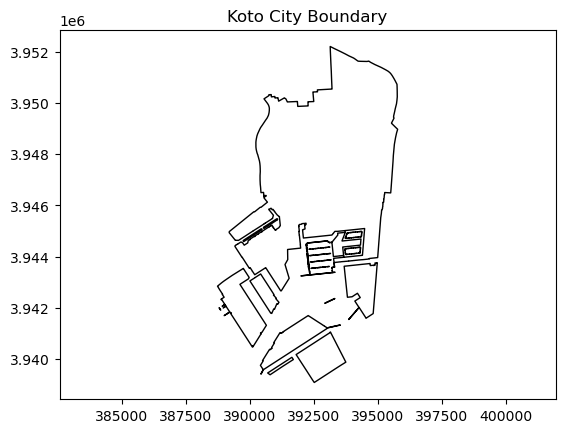

In [138]:
koto_city.plot(edgecolor="black", facecolor="none")
plt.title("Koto City Boundary")
plt.axis("equal")
plt.show()

In [139]:

koto_wgs84 = koto_city.to_crs(epsg=4326)  # Transform to WGS84 coordinate reference system
koto_geometry = koto_wgs84.geometry.union_all()
koto_bbox = tuple(koto_wgs84.total_bounds)  # Get the bounding box of Koto City in WGS84 coordinates

# print(f"Koto City Bounding Box (WGS84): {koto_bbox}")

In [140]:
#Connecting to the Planetary Computer STAC API and searching for Sentinel-2 imagery for Koto City
catalog = pystac_client.Client.open("https://planetarycomputer.microsoft.com/api/stac/v1")

# Search for Sentinel-2 imagery within the bounding box of Koto City
search = catalog.search(collections=["sentinel-2-l2a"],bbox=koto_bbox, 
                        datetime="2020-01-01/2020-12-31", query={"eo:cloud_cover": {"lt": 15}})

items = search.item_collection()



In [141]:
#Inspect items and their properties
# for item in items[:5]:  # Display the first 5 items for brevity
#     print(item.id, item.datetime, item.properties.get("eo:cloud_cover"))

#Signing assets for access to the Planetary Computer
signed_items = [planetary_computer.sign(item) for item in items]

In [142]:
#Loading spectral bands
bands = ["B02", "B03", "B04", "B08", "B11", "B12"]  # Blue, Green, Red, NIR bands, and SWIR bands

image_stack = stackstac.stack(signed_items, assets=bands, epsg=32654, resolution=10, 
                              bounds_latlon=koto_bbox)

koto_projected = koto_city.to_crs(epsg=32654)  # Transform Koto City geometry to match the image stack CRS  

#cloud filtered composite of the Sentinel-2 imagery for Koto City
composite = image_stack.median(dim="time", skipna=True).compute()

print(composite.shape)

(6, 1322, 712)


In [143]:
# Extracting bands and calculating land surface indices
blue = composite.sel(band="B02")
green = composite.sel(band="B03")
red = composite.sel(band="B04")
nir = composite.sel(band="B08")
swir1 = composite.sel(band="B11")
swir2 = composite.sel(band="B12")

ndvi = (nir - red) / (nir + red)
mndwi = (green - swir1) / (green + swir1)
ndbi = (swir1 - nir) / (swir1 + nir)
bsi = ((swir1 + red) - (nir + blue)) / ((swir1 + red) + (nir + blue))

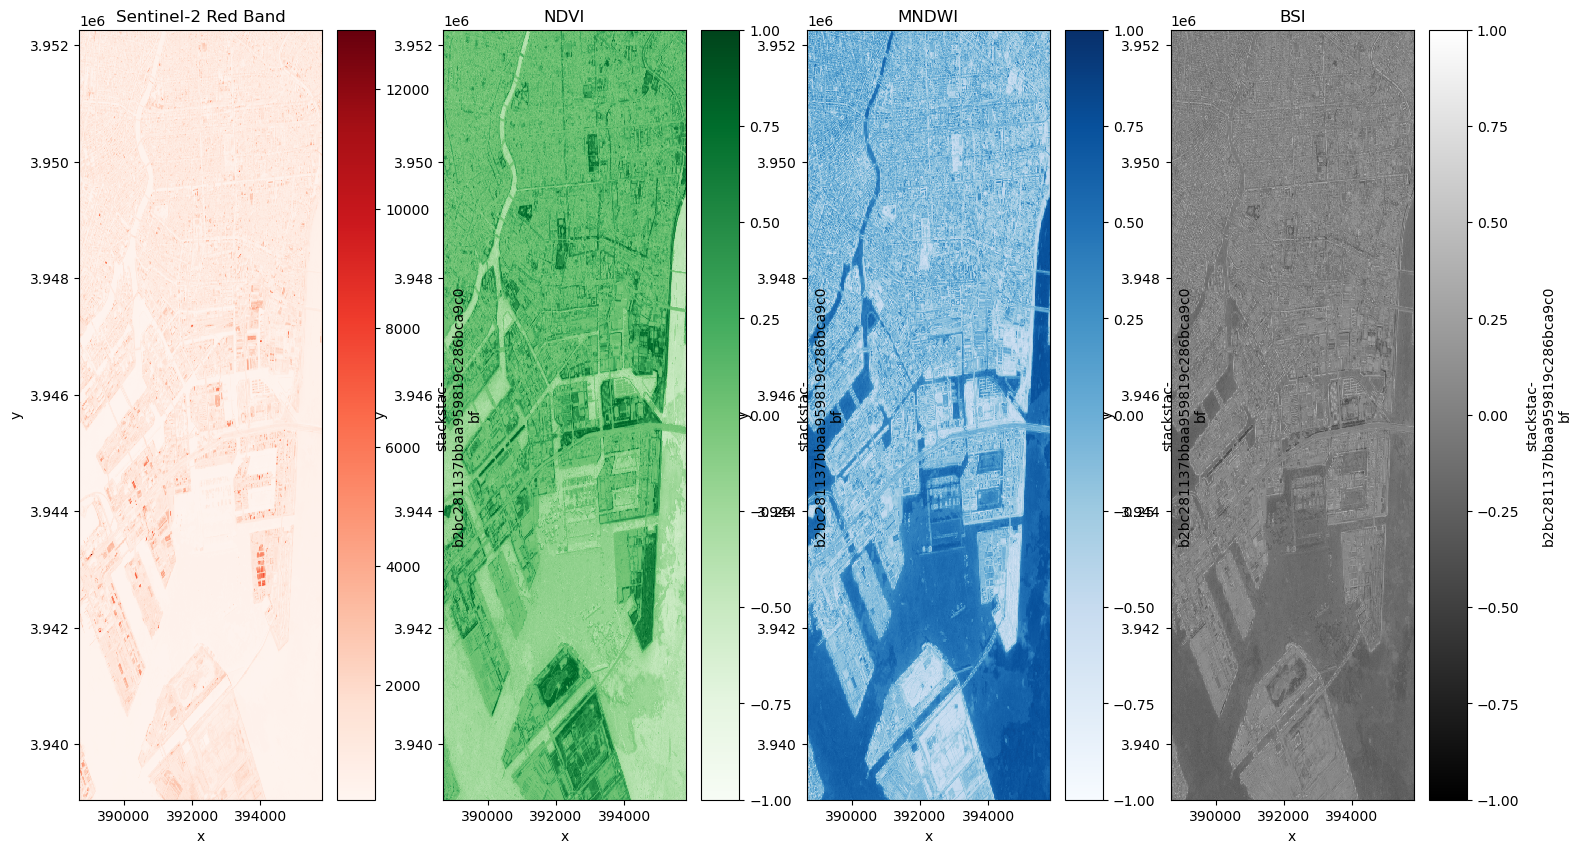

In [144]:
#plotting the calculated indices
fig, axes = plt.subplots(1, 4, figsize=(18, 10))

red.plot.imshow(ax=axes[0], cmap="Reds") # Plotting the Sentinel-2 Red Band showing the urban areas of Koto City
axes[0].set_title("Sentinel-2 Red Band")

ndvi.plot.imshow(ax=axes[1], cmap="Greens", vmin=-1, vmax=1)
axes[1].set_title("NDVI")

mndwi.plot.imshow(ax=axes[2], cmap="Blues", vmin=-1, vmax=1)
axes[2].set_title("MNDWI")

bsi.plot.imshow(ax=axes[3], cmap="gray", vmin=-1, vmax=1)
axes[3].set_title("BSI")

plt.show()

In [145]:
print(koto_bbox)

(np.float64(139.77134968899998), np.float64(35.58965563999998), np.float64(139.848226783), np.float64(35.70800763999999))


In [146]:
# Defining training data for land cover classification using Random Forest Classifier
from pyrosm import OSM

osm = OSM("koto.osm.pbf")  # Load the OSM data for Koto City

#Extracting building footprints and water bodies from OSM data
buildings = osm.get_buildings()
landuse = osm.get_landuse()
natural = osm.get_natural()
roads = osm.get_network(network_type="all")

In [147]:
#inspecting the extracted data fclass columns
print(f"Buildings columns: {buildings.columns}")
print(f"Landuse columns: {landuse.columns}")
print(f"Natural columns: {natural.columns}")
print(f"Roads columns: {roads.columns}")

Buildings columns: Index(['addr:city', 'addr:country', 'addr:housenumber', 'addr:housename',
       'addr:postcode', 'addr:place', 'addr:street', 'email', 'name',
       'opening_hours', 'operator', 'phone', 'ref', 'url', 'visible',
       'website', 'building', 'amenity', 'building:flats', 'building:levels',
       'building:material', 'building:min_level', 'building:use', 'craft',
       'height', 'internet_access', 'landuse', 'levels', 'office', 'shop',
       'source', 'start_date', 'wikipedia', 'id', 'timestamp', 'version',
       'tags', 'osm_type', 'geometry', 'changeset'],
      dtype='object')
Landuse columns: Index(['lat', 'lon', 'id', 'visible', 'changeset', 'tags', 'version',
       'timestamp', 'landuse', 'residential', 'geometry', 'osm_type',
       'construction', 'depot', 'industrial', 'port'],
      dtype='object')
Natural columns: Index(['lat', 'lon', 'id', 'visible', 'changeset', 'tags', 'version',
       'timestamp', 'natural', 'geometry', 'osm_type', 'water'],
    

In [148]:
#Assigning training labels based on OSM data for land cover classification
t_buildings = buildings.to_crs("EPSG:32654")[["geometry"]].copy()
t_buildings["class"] = "impervious"

t_vegetation = landuse.to_crs("EPSG:32654")
t_vegetation = t_vegetation[t_vegetation["landuse"].isin(["forest", "grass", "recreation_ground"])]
[["geometry"]].copy()
t_vegetation["class"] = "vegetation"

t_water = natural.to_crs("EPSG:32654")
t_water = t_water[t_water["water"].isin(["water", "river", "stream"])][["geometry"]].copy()
t_water["class"] = "water"

training_polygons = [t_buildings, t_vegetation, t_water]

In [149]:
# Convert roads to the projected CRS and buffer them into polygons, 
# clipping them to the Koto City boundary to create training polygons for the "impervious" class
koto_mask = koto_city.to_crs("EPSG:32654").geometry.union_all()

t_roads = roads.to_crs("EPSG:32654")

road_indices = t_roads.sindex.query(
    koto_mask,
    predicate="intersects"
)

t_roads = t_roads.iloc[road_indices].copy()
t_roads = gpd.clip(t_roads, koto_mask)

t_roads_polygons = t_roads[["geometry"]].copy()
t_roads_polygons["geometry"] = t_roads_polygons.geometry.buffer(3)
t_roads_polygons["class"] = "impervious"

# Soil classification for training data using OSM data, mostly construction sites, farmland, and other soil types. This will be used to train the Random Forest Classifier for land cover classification.
t_soil = landuse.to_crs("EPSG:32654")
t_soil = t_soil[t_soil["landuse"].isin(["construction", "farmland", "brownfield", "allotments"])]
t_soil = t_soil[["geometry"]].copy()
t_soil["class"] = "soil"

In [150]:
#Building a GeoDataFrame for training polygons by concatenating the individual class polygons
training_polygons = [t_buildings, t_vegetation, t_water, t_soil, t_roads_polygons]

training_polygons_gdf = gpd.GeoDataFrame(pd.concat(training_polygons, ignore_index=True), 
    geometry="geometry", crs="EPSG:32654")

In [151]:
# Sampling Sentinel-2 imagery for training data
# by extracting pixel values for each band and the calculated indices

feature_arrays = [blue.values, green.values, red.values, nir.values, swir1.values,
    swir2.values, ndvi.values, mndwi.values, ndbi.values, bsi.values]

image_features = np.stack(feature_arrays, axis=-1)
print(f"Image features shape: {image_features.shape}")

Image features shape: (1322, 712, 10)


In [152]:
from rasterio.features import geometry_mask
from affine import Affine

transform = Affine(float(composite.x[1] - composite.x[0]), 0, float(composite.x[0]),
    0, float(composite.y[1] - composite.y[0]), float(composite.y[0]))

training_features = []
training_labels = []

for _, sample in training_polygons_gdf.iterrows():
    mask = geometry_mask([sample.geometry],out_shape=image_features.shape[:2],
                        transform=transform, invert=True)

    pixels = image_features[mask]
    pixels = pixels[np.isfinite(pixels).all(axis=1)]

    training_features.append(pixels)
    training_labels.extend([sample["class"]] * len(pixels))

training_features = np.vstack(training_features)
training_labels = np.asarray(training_labels)

In [153]:
from sklearn.preprocessing import LabelEncoder

# Ensure the feature arrays are numeric
image_features = np.asarray(image_features, dtype=np.float32)
training_features = np.asarray(training_features, dtype=np.float32)

n_rows, n_cols, n_features = image_features.shape

# Remove invalid training rows
valid_training = np.isfinite(training_features).all(axis=1)

training_features_clean = training_features[valid_training]
training_labels_clean = np.asarray(training_labels)[valid_training]

# Flatten image features for scikit-learn
image_features_2d = image_features.reshape(-1, n_features)

# Only classify valid pixels inside Koto City
koto_pixels = koto_mask.reshape(-1)

valid_image = (koto_pixels & np.isfinite(image_features_2d).all(axis=1))

classifier = RandomForestClassifier(n_estimators=300, random_state=42, 
            class_weight="balanced",n_jobs=-1)

classifier.fit(training_features_clean, training_labels_clean)

# Use -1 as a numeric value for pixels outside Koto or invalid pixels
classified_flat = np.full(image_features_2d.shape[0], -1, dtype=np.int8)

# Convert class names to numeric codes
class_names = np.unique(training_labels_clean)
class_to_code = {class_name: code for code, class_name in enumerate(class_names)}

predicted_labels = classifier.predict(image_features_2d[valid_image])

classified_flat[valid_image] = np.array(
[class_to_code[label] for label in predicted_labels], dtype=np.int8)

classified = classified_flat.reshape(n_rows, n_cols)

print("Class codes:", class_to_code)
print("Classified shape:", classified.shape)

AttributeError: 'MultiPolygon' object has no attribute 'reshape'

In [ ]:
#Determining resolution of the classified image and calculating the area of each class in square kilometers
x_res = abs(float(composite.x[1] - composite.x[0]))
y_res = abs(float(composite.y[1] - composite.y[0]))
pixel_area_m2 = x_res * y_res
pixel_area_km2 = pixel_area_m2 / 1e6

In [ ]:
valid_classified = classified[classified >= 0]

class_counts = pd.Series(valid_classified).value_counts().sort_index()

area_table = pd.DataFrame({
    "class_code": class_counts.index,
    "pixel_count": class_counts.values
})

area_table["class"] = area_table["class_code"].map(
    {code: name for name, code in class_to_code.items()}
)

area_table["area_m2"] = (
    area_table["pixel_count"] * pixel_area_m2
)

area_table["area_km2"] = (
    area_table["area_m2"] / 1_000_000
)

area_table["fraction"] = (
    area_table["area_m2"] /
    area_table["area_m2"].sum()
)

print(area_table)

   class_code  pixel_count       class     area_m2  area_km2  fraction
0           0       344936  impervious  34493600.0   34.4936  0.780964
1           1         5744        soil    574400.0    0.5744  0.013005
2           2        54458  vegetation   5445800.0    5.4458  0.123297
3           3        36542       water   3654200.0    3.6542  0.082734


In [ ]:
# # Calculating the percentage of impervious surface area within Koto City
# valid_area = ~np.isnan(classified)


# impervious_fraction = ( np.sum((classified == "impervious") & valid_area)
#     / np.sum(valid_area))
# print(f"Impervious surface fraction in Koto City: {impervious_fraction:.4f} ({impervious_fraction*100:.2f}%)")

# # Extracting impervious area, vegetation area, and water area from the classified image
# impervious_area = (classified == "impervious").astype(np.uint8)
# vegetation_area = (classified == "vegetation").astype(np.uint8)
# water_area = (classified == "water").astype(np.uint8)

In [ ]:
# # Plotting the classified land cover map for Koto City
# plt.figure(figsize=(12, 10))
# plt.imshow(classified, cmap="tab10", interpolation="nearest")
# plt.title("Classified Land Cover Map for Koto City")
# plt.axis("off")
# # Create a legend for the classified land cover map
# from matplotlib.patches import Patch
# legend_elements = [Patch(facecolor="tab:blue", label="Impervious"),
#     Patch(facecolor="tab:green", label="Vegetation"), Patch(facecolor="tab:orange", label="Water")]
# plt.legend(handles=legend_elements, loc="upper right")


In [ ]:
# Validating the classification using a confusion matrix and classification report
# Splitting the training data into training and testing sets

# X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


Image feature shape: (1322, 712, 10)


TypeError: Image data of dtype object cannot be converted to float

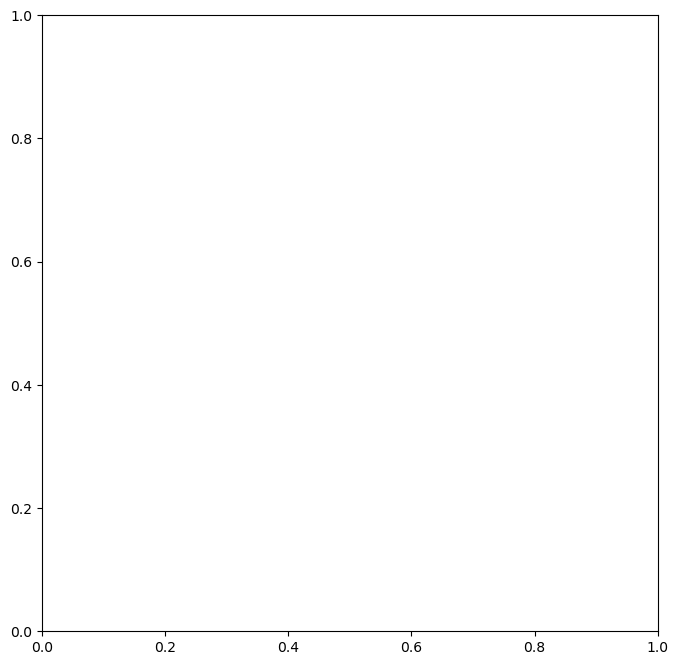

In [ ]:
from rasterio.transform import from_bounds
TARGET_CRS = "EPSG:32654"

# 1. Prepare the Koto City mask
koto_projected = koto_city.to_crs(TARGET_CRS)
koto_geometry = koto_projected.geometry.union_all()

# 2. Build the image feature cube: rows x columns x features
feature_names = [
    "blue", "green", "red", "nir", "swir1", "swir2",
    "ndvi", "mndwi", "ndbi", "bsi"
]

feature_arrays = [
    blue.values, green.values, red.values, nir.values,
    swir1.values, swir2.values, ndvi.values,
    mndwi.values, ndbi.values, bsi.values
]

image_features = np.stack(feature_arrays, axis=-1)

n_rows, n_cols, n_features = image_features.shape
print("Image feature shape:", image_features.shape)

# 3. Create the raster transform from the image coordinates
x_values = composite.x.values
y_values = composite.y.values

x_resolution = abs(float(x_values[1] - x_values[0]))
y_resolution = abs(float(y_values[1] - y_values[0]))

left = float(x_values.min()) - x_resolution / 2
right = float(x_values.max()) + x_resolution / 2
bottom = float(y_values.min()) - y_resolution / 2
top = float(y_values.max()) + y_resolution / 2

transform = from_bounds(
    left, bottom, right, top, n_cols, n_rows
)

# 4. Mask pixels outside Koto City
koto_mask = geometry_mask(
    [koto_geometry],
    out_shape=(n_rows, n_cols),
    transform=transform,
    invert=True
)

# 5. Flatten the image for Random Forest prediction
image_features_2d = image_features.reshape(-1, n_features)
koto_pixels = koto_mask.reshape(-1)

valid_pixels = (
    koto_pixels
    & np.isfinite(image_features_2d).all(axis=1)
)

# 6. Train the classifier
classifier = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

classifier.fit(training_features, training_labels)

# 7. Classify only valid pixels
classified_flat = np.full(
    image_features_2d.shape[0],
    None,
    dtype=object
)

classified_flat[valid_pixels] = classifier.predict(
    image_features_2d[valid_pixels]
)

classified = classified_flat.reshape(n_rows, n_cols)

# 8. Plot the classification
plt.figure(figsize=(10, 8))
plt.imshow(classified, interpolation="nearest", cmap="tab10")
plt.title("Koto City Land-Cover Classification")
plt.axis("off")
plt.show()

TypeError: Image data of dtype object cannot be converted to float

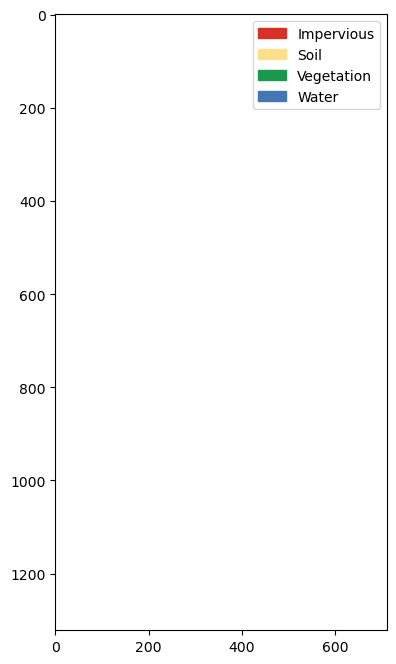

In [ ]:
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

class_colors = {
    "impervious": "#d73027",
    "vegetation": "#1a9850",
    "water": "#4575b4",
    "soil": "#fee08b"
}

class_to_code = {
    class_name: code
    for code, class_name in enumerate(class_names)
}

display_array = np.full(classified.shape, np.nan)

for class_name, code in class_to_code.items():
    display_array[classified == code] = code

colors = [
    class_colors[class_name]
    for class_name in class_names
]

plt.figure(figsize=(10, 8))
plt.imshow(
    display_array,
    cmap=ListedColormap(colors),
    vmin=0,
    vmax=len(class_names) - 1
)

legend_handles = [
    Patch(color=class_colors[class_name], label=class_name.title())
    for class_name in class_names
]

plt.legend(handles=legend_handles, loc="upper right")
plt.imshow(classified, cmap=ListedColormap(colors), vmin=0, vmax=len(class_names) - 1)
plt.title("Koto City Surface Classification")
plt.axis("off")
plt.show()